# Notebook 01 — EDA: AEMET

**Objetivo del notebook**: Analizar la distribución espacial de las estaciones de AEMET y seleccionar aquellas ubicadas en las provincias relevantes para la cuenca del Júcar.

Este análisis permite evaluar la cobertura geográfica de la red AEMET y compararla posteriormente con la red SAIH-CHJ.

In [13]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys
import folium

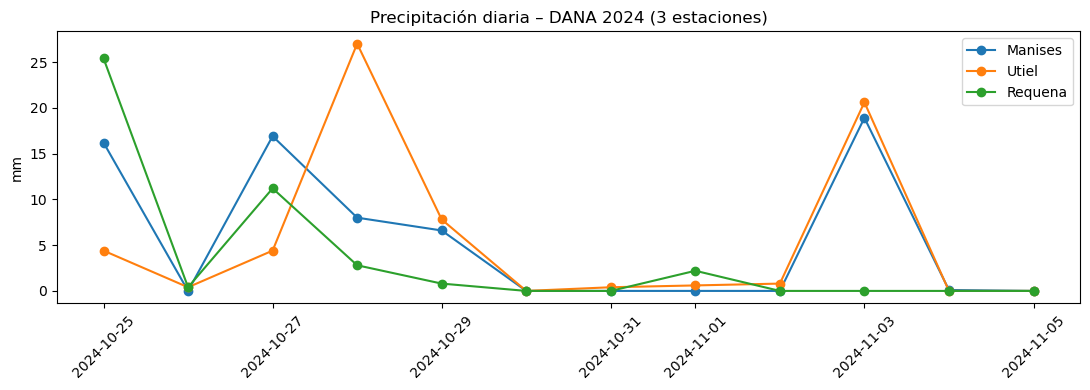

In [14]:
ruta = Path("../data/raw/aemet")
estaciones = {"8414A": "Manises", "8293X": "Utiel", "8175": "Requena"}

dfs = []
for codigo, nombre in estaciones.items():
    with open(ruta / f"{codigo}_dana_2024.json", encoding="utf-8") as f:
        d = pd.DataFrame(json.load(f))
    d["fecha"] = pd.to_datetime(d["fecha"])
    d["prec"] = pd.to_numeric(d["prec"].str.replace(",", "."), errors="coerce")
    d["estacion"] = nombre
    dfs.append(d[["fecha", "prec", "estacion"]])

df = pd.concat(dfs, ignore_index=True)

fig, ax = plt.subplots(figsize=(11, 4))
for nombre in estaciones.values():
    sub = df[df["estacion"] == nombre]
    ax.plot(sub["fecha"], sub["prec"], marker="o", label=nombre)
ax.set_title("Precipitación diaria – DANA 2024 (3 estaciones)")
ax.set_ylabel("mm")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Se puede observar como el día 29 de octubre no se puede apreciar realmente la inundación que hubo.

Más adelante, a lo largo del proyecto se va describiendo el porqué y la necesidad de la utilización de diferentes fuentes.

## 1. Carga y preparación del inventario de estaciones

Se utiliza el inventario oficial de AEMET para obtener la localización de las estaciones meteorológicas disponibles.

Las coordenadas se transforman a formato decimal para facilitar su uso en análisis geoespacial y representación cartográfica.

In [15]:
sys.path.insert(0, "..")
from src.ingest.aemet import parse_coord

with open("../data/raw/aemet/inventario_estaciones.json", encoding="utf-8") as f:
    inv = json.load(f)

inv_df = pd.DataFrame(inv)
print(f"Total estaciones en España: {len(inv_df)}")
inv_df.head()

Total estaciones en España: 947


,latitud,provincia,altitud,indicativo,nombre,indsinop,longitud
0,394924N,ILLES BALEARS,490,B013X,"ESCORCA, LLUC",08304,025309E
1,394744N,BALEARES,5,B051A,"SÓLLER, PUERTO",08316,024129E
2,394121N,ILLES BALEARS,60,B087X,BANYALBUFAR,,023046E
3,393446N,BALEARES,52,B103B,ANDRATX - SANT ELM,,022208E
4,393305N,BALEARES,50,B158X,"CALVIÀ, ES CAPDELLÀ",,022759E


## 2. Selección de estaciones relevantes para el área de estudio

Se filtran únicamente las provincias que forman parte de la cuenca del Júcar o que se encuentran en su entorno inmediato.

El objetivo es trabajar exclusivamente con estaciones potencialmente relevantes para el episodio DANA de octubre de 2024.

In [16]:
provincias_jucar = ["VALENCIA", "CUENCA", "ALBACETE", "CASTELLON", "TERUEL"]
red = inv_df[inv_df["provincia"].isin(provincias_jucar)].copy()

# Parseamos coordenadas
red["lat"] = red["latitud"].apply(parse_coord)
red["lon"] = red["longitud"].apply(parse_coord)
red["altitud"] = pd.to_numeric(red["altitud"], errors="coerce")

print(f"Estaciones en la zona de la cuenca del Júcar: {len(red)}")
print(red.groupby("provincia").size())

Estaciones en la zona de la cuenca del Júcar: 77
provincia
ALBACETE     12
CASTELLON    11
CUENCA       15
TERUEL       18
VALENCIA     21
dtype: int64


En la provincia de Valencia AEMET solo tiene 21 estaciones climatológicas en este inventario. Son las "principales", las que dan datos diarios estables. No son todos los pluviómetros que existen — los pluviómetros de SAIH-CHJ son muchos más.

## 3. Representación cartográfica de la red AEMET

Se genera un mapa interactivo para visualizar la distribución espacial de las estaciones.

Cada provincia se representa mediante un color diferente con el fin de identificar posibles concentraciones o zonas con menor cobertura.

In [17]:
m = folium.Map(location=[39.5, -1.5], zoom_start=8, tiles="OpenStreetMap")

colores = {
    "VALENCIA": "red",
    "CUENCA": "blue",
    "ALBACETE": "green",
    "CASTELLON": "orange",
    "TERUEL": "purple",
}

# Estaciones ya descargadas
descargadas = {"8414A", "8293X", "8175"}

for _, row in red.iterrows():
    if pd.isna(row["lat"]) or pd.isna(row["lon"]):
        continue
    color = colores.get(row["provincia"], "gray")
    radio = 9 if row["indicativo"] in descargadas else 5
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=radio,
        color=color,
        fill=True,
        fill_opacity=0.7,
        popup=(
            f"<b>{row['nombre']}</b><br>"
            f"Código: {row['indicativo']}<br>"
            f"Provincia: {row['provincia']}<br>"
            f"Altitud: {row['altitud']} m"
        ),
    ).add_to(m)

m

## 4. Exportación del resultado

El mapa generado se almacena en formato HTML para poder consultarlo desde un navegador sin necesidad de ejecutar nuevamente el notebook.

In [18]:
from pathlib import Path

# Guarda el mapa como HTML
out = Path("../data/processed")
out.mkdir(parents=True, exist_ok=True)
mapa_path = out / "mapa_estaciones_aemet.html"
m.save(str(mapa_path))
print(f"Mapa guardado en: {mapa_path.resolve()}")

Mapa guardado en: C:\Users\Maria\Documents\tfm-flood-warning\data\processed\mapa_estaciones_aemet.html
